In [ ]:
import sys
sys.path.append('..')
import itertools

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import bioframe as bf

from utils.plotting import genomic_labels
from notebooks.func_iou import generate_positions, match_by_iou, unique_pairs

In [ ]:
# Overlap parameters
iou_threshold = 0  # ANY overlap

resolution = 50000 # standardize

buffer_radius = 3 * 50000

# FUN
f_pred_fun_replihic_bedpe = f"/nfs/turbo/umms-minjilab/sionkim/miajet_revision/other_methods/FUN_Repli-HiC_K562_WT_totalS_{resolution // 1e3:.0f}kb/FUN-pred_{resolution}_1.3.bedpe"
f_pred_fun_replihic_tab = f"/nfs/turbo/umms-minjilab/sionkim/miajet_revision/other_methods/FUN_Repli-HiC_K562_WT_totalS_{resolution // 1e3:.0f}kb/FUN-pred_{resolution}_1.3.tab"

# FONTANKA
# for Repli Hi-C use weak thresholded
f_pred_fontanka_replihic = f"/nfs/turbo/umms-minjilab/sionkim/miajet_revision/other_methods/FONTANKA_ws-small_Repli-HiC_K562_WT_totalS_{resolution // 1e3:.0f}kb.{resolution}.predicted.fountains.thresholded-weak.tsv"

# MIA-JET
output_name = "v2.0.3"
result_type_replihic = "q_val_0.5" # for RepliHi-C
f_pred_miajet_replihic_summary = f"/nfs/turbo/umms-minjilab/sionkim/miajet_revision/miajet/output_{output_name}/Repli-HiC_K562_WT_totalS_chr_combined_{genomic_labels(resolution)}/Repli-HiC_K562_WT_totalS_chr_combined_{result_type_replihic}_{genomic_labels(resolution)}_summary_table.csv"
f_pred_miajet_replihic_expanded = f"/nfs/turbo/umms-minjilab/sionkim/miajet_revision/miajet/output_{output_name}/Repli-HiC_K562_WT_totalS_chr_combined_{genomic_labels(resolution)}/Repli-HiC_K562_WT_totalS_chr_combined_{result_type_replihic}_{genomic_labels(resolution)}_expanded_table.csv"

# Type I Annotation
f_pred_type_annotation = f"/nfs/turbo/umms-minjilab/downloaded_data/miajet_data_temp/adj7606_data_s2.xlsx"

# Output directory
analysis_dir = f"/nfs/turbo/umms-minjilab/sionkim/miajet_revision/analysis_{output_name}"

In [ ]:
chrom_sizes = bf.fetch_chromsizes("hg19", as_bed=True)
common_chroms = chrom_sizes['chrom'].tolist()
common_chroms.remove("chrY")  # remove chrY if present

In [ ]:
df_annot_1 = pd.read_excel(f_pred_type_annotation, sheet_name="Data S2-Type-I in K562", header=None, skiprows=3, 
              names=['Number', "chrom", "start_center", "end_center", 'upstream_start', 'upstream_end', 'downstream_start', 'downstream_end'])
df_annot_2 = pd.read_excel(f_pred_type_annotation, sheet_name="Data S2-Type-II in K562", header=None, skiprows=3, 
              names=['Number', "chrom", "start_center", "end_center", 'upstream_start', 'upstream_end', 'downstream_start', 'downstream_end'])

## Processing

In [ ]:
# Process Liu et al. annotations

# Similar to fun, we have extrusion_x, extrusion_y but they are called upstream, downstream

# For Type 1
df_annot_1['extrusion_x'] = (df_annot_1['downstream_start'] + df_annot_1['downstream_end']) / 2
df_annot_1['extrusion_y'] = (df_annot_1['upstream_start'] + df_annot_1['upstream_end']) / 2
assert np.all(df_annot_1['extrusion_x'] >= df_annot_1['extrusion_y']), "Extrusion x should be greater than or equal to extrusion y"

df_annot_1['root'] = (df_annot_1['start_center'] + df_annot_1['end_center']) / 2
df_annot_1['unique_id'] = df_annot_1['Number'].astype(str) + "_typeI"

df_minimal_1 = df_annot_1[['unique_id', "chrom", "root", 'extrusion_x', 'extrusion_y']]

df_positions_1 = generate_positions(df_minimal_1, resolution)

# Repeat for type 2
df_annot_2['extrusion_x'] = (df_annot_2['downstream_start'] + df_annot_2['downstream_end']) / 2
df_annot_2['extrusion_y'] = (df_annot_2['upstream_start'] + df_annot_2['upstream_end']) / 2
assert np.all(df_annot_2['extrusion_x'] >= df_annot_2['extrusion_y']), "Extrusion x should be greater than or equal to extrusion y"

df_annot_2['root'] = (df_annot_2['start_center'] + df_annot_2['end_center']) / 2
df_annot_2['unique_id'] = df_annot_2['Number'].astype(str) + "_typeII"

df_minimal_2 = df_annot_2[['unique_id', "chrom", "root", 'extrusion_x', 'extrusion_y']]

df_positions_2 = generate_positions(df_minimal_2, resolution)

In [ ]:
# Process MIA-Jet
# expanded table = per-jet coordinates used for overlap; summary table = one row per jet (total N)
miajet_positions = pd.read_csv(f_pred_miajet_replihic_expanded, comment="#")
miajet_table = pd.read_csv(f_pred_miajet_replihic_summary, comment="#")

In [ ]:
# Process fun

fun_bedpe = pd.read_csv(f_pred_fun_replihic_bedpe, sep="\t")
fun_table = pd.read_csv(f_pred_fun_replihic_tab, sep="\t")

fun_bedpe["extrusion_x"] = (fun_bedpe["y1"] + fun_bedpe["y2"]) / 2
fun_bedpe["extrusion_y"] = (fun_bedpe["x1"] + fun_bedpe["x2"]) / 2
assert np.all(fun_bedpe["extrusion_x"] >= fun_bedpe["extrusion_y"])

fun_table["root"] = (fun_table["start"] + fun_table["end"]) / 2

fun_minimal = fun_bedpe.copy()
fun_minimal["root"] = fun_table["root"]

fun_minimal["unique_id"] = fun_minimal.index
fun_minimal["chrom"] = fun_table["chrom"]

fun_minimal = fun_minimal[["unique_id", "chrom", "root", "extrusion_x", "extrusion_y"]]

fun_positions = generate_positions(fun_minimal, resolution)
fun_positions["unique_id"] = fun_positions["unique_id"].astype(int)

In [ ]:
# Process fontanka
fontanka_table = pd.read_csv(f_pred_fontanka_replihic, sep="\t", index_col=0)
fontanka_table.dropna(inplace=True, how="any")
fontanka_table.reset_index(inplace=True, drop=True)

fontanka_table["root"] = (fontanka_table["end"] + fontanka_table["start"]) / 2
fontanka_table["unique_id"] = fontanka_table.index
fontanka_table["extrusion_x"] = fontanka_table["window_end"]
fontanka_table["extrusion_y"] = fontanka_table["window_start"]
assert np.all(fontanka_table["extrusion_x"] >= fontanka_table["extrusion_y"])

fontanka_minimal = fontanka_table[["unique_id", "chrom", "root", "extrusion_x", "extrusion_y"]]

fontanka_positions = generate_positions(fontanka_minimal, resolution)
fontanka_positions["unique_id"] = fontanka_positions["unique_id"].astype(int)  

## Intersection

In [ ]:
names = ["Type I", "Type II", "MIA-Jet", "Fun", "Fontanka"]

tables = [
    df_annot_1,
    df_annot_2,
    miajet_table,
    fun_table,
    fontanka_table
]

positions = [
    df_positions_1,
    df_positions_2,
    miajet_positions,
    fun_positions,
    fontanka_positions
]

table_dict = dict(zip(names, tables))
position_dict = dict(zip(names, positions))

In [ ]:
# COMPUTE OVERLAPS
results = pd.DataFrame(index=names, columns=names, dtype=int).fillna(0)
# fill main diagonal with the total number of jets from each method
for n in names:
    results.loc[n, n] = len(table_dict[n])

# Only the Type x method overlaps are plotted, so only those pairs are computed
for n1, n2 in itertools.product(["Type I", "Type II"], ["MIA-Jet", "Fun", "Fontanka"]):

    genome_wide_overlap = 0

    for chrom in common_chroms:

        # IOU method is per-chromosome so filter each table by chromosome
        t1 = position_dict[n1].loc[position_dict[n1]["chrom"] == chrom]
        t2 = position_dict[n2].loc[position_dict[n2]["chrom"] == chrom]

        if t1.empty or t2.empty:
            # if any of the two tables are empty then no need to check for overlaps.. there is none
            continue

        # Compute the pairs of jets in each direction
        pairs12 = match_by_iou(t1, t2, buffer_radius=buffer_radius, iou_threshold=iou_threshold, x_label="x (bp)", y_label="y (bp)")
        pairs21 = match_by_iou(t2, t1, buffer_radius=buffer_radius, iou_threshold=iou_threshold, x_label="x (bp)", y_label="y (bp)")

        # Construct graph and find unique pairs
        pairs = unique_pairs(pairs12, pairs21, method="optimal")

        genome_wide_overlap += len(pairs)

    # Update results table
    results.loc[n1, n2] = genome_wide_overlap
    results.loc[n2, n1] = genome_wide_overlap  # symmetric

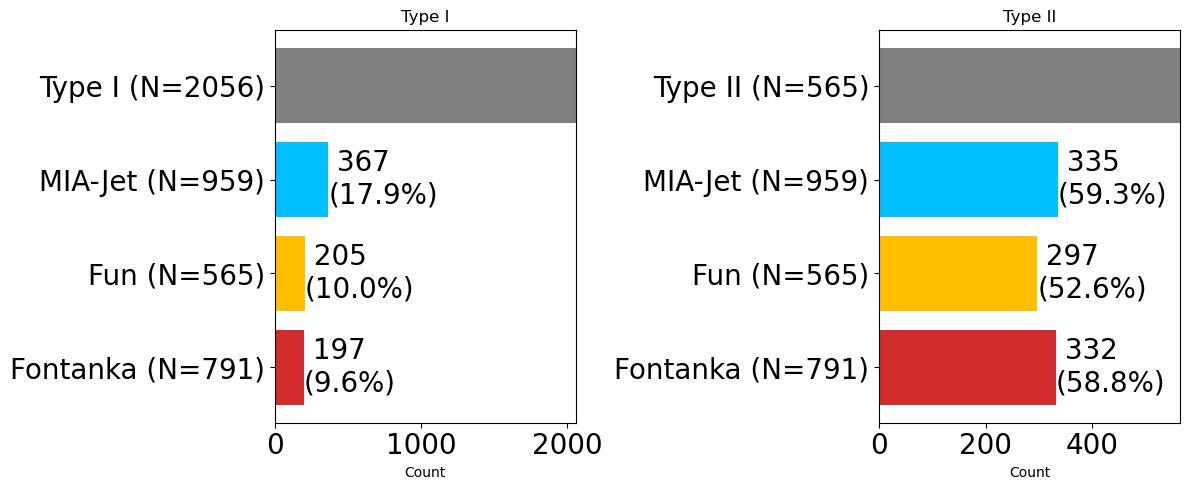

In [ ]:
types = ["Type I", "Type II"]
intersect_sets = ["MIA-Jet", "Fun", "Fontanka"]

# Labels with N taken from the diagonal (total of each set)
type_labels = [f"{t} (N={results.loc[t, t]:.0f})" for t in types]
intersect_labels = [f"{s} (N={results.loc[s, s]:.0f})" for s in intersect_sets]

# Consistent colors: gray = the Type's own total, then one color per intersecting set
total_color = "tab:gray"
set_colors = ["#00bfff", "#ffbf00", "#d22b2b"]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))  # sharex left off so each panel scales independently

for ax, t, t_label in zip(axes, types, type_labels):
    # Bar 1 = total of this Type; bars 2-4 = intersections with MIA-Jet / Fun / Fontanka
    labels = [t_label] + intersect_labels
    values = [results.loc[t, t]] + [results.loc[s, t] for s in intersect_sets]
    colors = [total_color] + set_colors

    y = np.arange(len(labels))
    ax.barh(y, values, color=colors)
    ax.set_yticks(y)
    ax.set_yticklabels(labels)
    ax.invert_yaxis()              # puts the total bar on top
    ax.set_xlabel("Count")
    ax.set_title(t)

    # value annotations at the end of each bar
    for i, (yi, v) in enumerate(zip(y, values)):
        if i > 0:
            ax.text(v, yi, f" {v:.0f}\n({v/results.loc[t, t]*100:.1f}%)", va="center", ha="left", fontsize=20)

    # a little headroom so annotations don't clip
    ax.set_xlim(0, max(values))

    ax.tick_params(axis="both", labelsize=20)

plt.tight_layout()


plt.savefig(f"{analysis_dir}/K562_replihic_overlap-bar-miajet-{resolution}.png",
            dpi=300, bbox_inches="tight")

plt.show()